<a href="https://colab.research.google.com/github/Iucasoa/Sistemas-Inteligentes/blob/main/problema1-regressao-linear/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problema 1: Regressão Linear Múltipla para Previsão de Produção de Energia

Neste trabalho vamos construir um modelo de regressão linear múltipla para prever a potência elétrica de saída (`PE`) de uma usina termoelétrica de ciclo combinado a partir de quatro variáveis medidas por sensores ambientais. O modelo tem a forma:

$$
PE = \theta_0 + \theta_1 \, AT + \theta_2 \, V + \theta_3 \, AP + \theta_4 \, RH
$$

O fluxo segue o notebook de regressão linear da disciplina (`05_Regressao_Linear.ipynb`).

Inicialmente, vamos importar as bibliotecas:

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

Realizando algumas configurações nos plots:

In [2]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 5)

# Pasta onde as figuras usadas no relatório são salvas
os.makedirs("figuras", exist_ok=True)

## 1. Conjunto de Dados

Vamos utilizar o *dataset* **UCI Combined Cycle Power Plant (CCPP)**, com 9.568 amostras coletadas ao longo de 6 anos. Ele é carregado diretamente do repositório da UCI pelo pacote `ucimlrepo` (no Google Colab é necessário instalá-lo):

In [ ]:
%pip install -q --disable-pip-version-check ucimlrepo

In [4]:
from ucimlrepo import fetch_ucirepo

ccpp = fetch_ucirepo(id=294)

df = ccpp.data.features.copy()
df["PE"] = ccpp.data.targets
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


* `AT`: Temperatura ambiente (°C)
* `V`: Vácuo de exaustão (cm Hg)
* `AP`: Pressão atmosférica (mbar)
* `RH`: Umidade relativa (%)
* `PE`: Energia elétrica líquida horária de saída (MW) — **variável alvo**

A quantidade de amostras e de variáveis pode ser obtida como:

In [5]:
print(f"Quantidade de amostras = {df.shape[0]}")
print(f"Quantidade de colunas = {df.shape[1]}")

Quantidade de amostras = 9568
Quantidade de colunas = 5


## 2. Pré-processamento

### 2.1 Dados incompletos

Primeiro **diagnosticamos** se existem valores faltantes:

In [6]:
print("Faltantes por coluna:")
print(df.isna().sum())

Faltantes por coluna:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


Não há valores faltantes, então não é necessário remover linhas nem imputar valores.

### 2.2 Dados redundantes

Verificando se existem linhas duplicadas, que são registros redundantes:

In [7]:
print("Linhas duplicadas:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
print("Formato após remover duplicatas:", df.shape)

Linhas duplicadas: 41
Formato após remover duplicatas: (9527, 5)


### 2.3 Escala das variáveis

In [8]:
display(df.describe().round(2))

,AT,V,AP,RH,PE
count,9527.00,9527.00,9527.00,9527.00,9527.00
mean,19.66,54.29,1013.24,73.33,454.34
std,7.44,12.69,5.94,14.61,17.04
min,1.81,25.36,992.89,25.56,420.26
25%,13.53,41.74,1009.08,63.38,439.75
50%,20.35,52.08,1012.92,75.00,451.52
75%,25.71,66.51,1017.20,84.85,468.36
max,37.11,81.56,1033.30,100.16,495.76


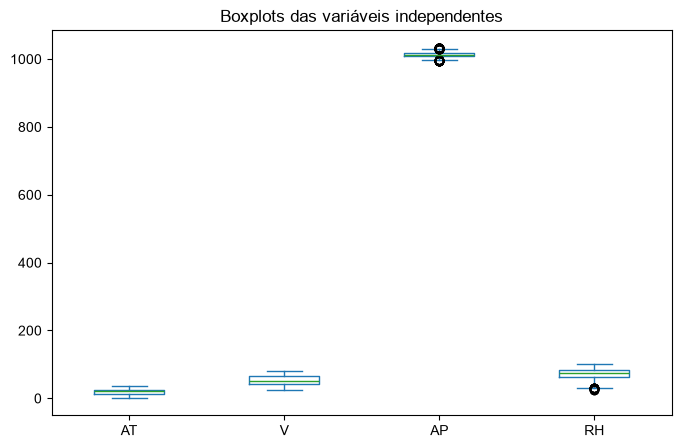

In [9]:
features = ["AT", "V", "AP", "RH"]

df[features].plot(kind="box")
plt.title("Boxplots das variáveis independentes")
plt.grid(False)
plt.savefig("figuras/boxplot_atributos.png", dpi=150, bbox_inches="tight")
plt.show()

As variáveis possuem ordens de grandeza muito diferentes entre si (por exemplo, `AP` em torno de 1.000 mbar e `AT` entre 2 °C e 37 °C). Por isso, as variáveis independentes serão **padronizadas** (*z-score*) após a divisão em treino e teste.

## 3. Tarefa 1: Correlação entre as variáveis independentes e `PE`

Calculando a correlação de Pearson entre cada variável independente e a variável dependente `PE`:

In [10]:
corr = df.corr()

corr_pe = corr["PE"].drop("PE")
print(corr_pe.sort_values(key=abs, ascending=False).round(3))

AT   -0.948
V    -0.870
AP    0.519
RH    0.391
Name: PE, dtype: float64


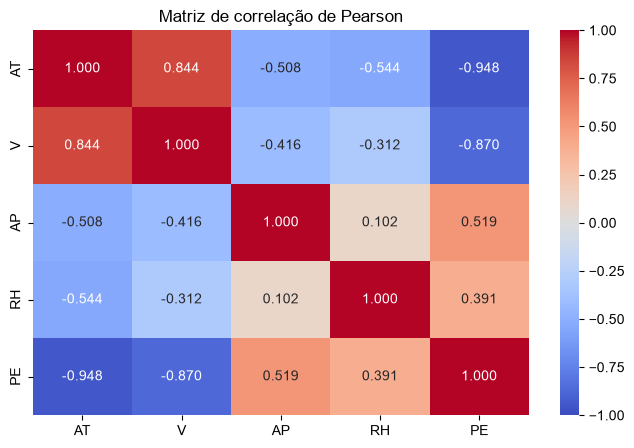

In [11]:
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlação de Pearson")
plt.savefig("figuras/matriz_correlacao.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Tarefa 2: Correlação entre as variáveis independentes

Agora vamos olhar apenas a correlação das variáveis independentes entre si, procurando pares com correlação forte ($|r| > 0{,}7$), que indicam **multicolinearidade** (informação redundante entre variáveis):

In [12]:
corr_X = df[features].corr()
display(corr_X.round(3))

alta = [(i, j, round(corr_X.loc[i, j], 3))
        for i in features for j in features
        if i < j and abs(corr_X.loc[i, j]) > 0.7]
print("Pares com correlação forte:", alta)

,AT,V,AP,RH
AT,1.000,0.844,-0.508,-0.544
V,0.844,1.000,-0.416,-0.312
AP,-0.508,-0.416,1.000,0.102
RH,-0.544,-0.312,0.102,1.000


Pares com correlação forte: [('AT', 'V', np.float64(0.844))]


## 5. Tarefa 3: Modelo de Regressão Linear Múltipla

Vamos dividir nosso conjunto de dados em treinamento (80%) e teste (20%) utilizando a função `train_test_split()`:

In [13]:
X = df[features]
y = df["PE"]

X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2, random_state=42
)

print(f"Tamanho do dataset = {X.shape[0]} amostras")
print(f"Quantidade de amostras de treinamento = {X_train.shape[0]} amostras")
print(f"Quantidade de amostras de teste = {X_test.shape[0]} amostras")

Tamanho do dataset = 9527 amostras
Quantidade de amostras de treinamento = 7621 amostras
Quantidade de amostras de teste = 1906 amostras


Realizando a padronização ($z = (x - \mu)/\sigma$). Os parâmetros do `StandardScaler` são aprendidos **apenas no treino** (`fit_transform`) e depois aplicados ao teste (`transform`), evitando o vazamento de dados (*data leakage*):

In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

E por fim, vamos utilizar o modelo `LinearRegression()` e o método `fit()` para ajustar os parâmetros do modelo:

In [15]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-14.67, -2.98, 0.37, -2.3 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,454.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[136.1 , 83.51, 64.76, 28.18]"


Os coeficientes $\theta_1, \theta_2, \theta_3, \theta_4$ (variáveis padronizadas) podem ser determinados como:

In [16]:
theta = model.coef_
print(pd.Series(theta, index=features).round(4))

AT   -14.6695
V     -2.9798
AP     0.3737
RH    -2.2977
dtype: float64


Já o coeficiente $\theta_0$ é obtido como:

In [17]:
theta_0 = model.intercept_
theta_0

np.float64(454.33761317412416)

Como as variáveis estão padronizadas, os coeficientes acima são comparáveis entre si. Para interpretá-los nas unidades originais (MW por °C, MW por mbar etc.), basta desfazer a padronização: $\theta_j^{orig} = \theta_j / \sigma_j$ e $\theta_0^{orig} = \theta_0 - \sum_j \theta_j \mu_j / \sigma_j$:

In [18]:
theta_orig = theta / scaler.scale_
theta_0_orig = theta_0 - np.sum(theta * scaler.mean_ / scaler.scale_)

print(pd.Series(theta_orig, index=features).round(4))
print(f"\nPE = {theta_0_orig:.4f} "
      + " ".join(f"{t:+.4f}*{v}" for t, v in zip(theta_orig, features)))

AT   -1.9767
V    -0.2349
AP    0.0630
RH   -0.1570
dtype: float64

PE = 453.5863 -1.9767*AT -0.2349*V +0.0630*AP -0.1570*RH


## 6. Tarefa 4: Avaliação do Modelo

O diagnóstico é sempre feito no conjunto de teste. Vamos calcular o $R^2$, o RMSE ($\sqrt{MSE}$) e o MAE:

In [19]:
y_pred = model.predict(X_test_scaled)

mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(y_test, y_pred)
r2   = r2_score(y_test, y_pred)

print(f"Coeficiente de determinação (R²): {r2:.4f}")
print(f"Raiz do erro quadrático médio (RMSE): {rmse:.4f} MW")
print(f"Erro absoluto médio (MAE): {mae:.4f} MW")

Coeficiente de determinação (R²): 0.9284
Raiz do erro quadrático médio (RMSE): 4.5875 MW
Erro absoluto médio (MAE): 3.6215 MW


Para ter uma referência do tamanho do erro, vamos compará-lo com a média e a faixa de `PE`:

In [20]:
print(f"Média de PE: {y.mean():.2f} MW | faixa: {y.min():.2f} a {y.max():.2f} MW")
print(f"RMSE relativo à média: {100 * rmse / y.mean():.2f}%")
print(f"RMSE relativo à faixa: {100 * rmse / (y.max() - y.min()):.2f}%")

Média de PE: 454.34 MW | faixa: 420.26 a 495.76 MW
RMSE relativo à média: 1.01%
RMSE relativo à faixa: 6.08%


Comparando com as métricas no conjunto de treinamento, para verificar se há sobreajuste (*overfitting*):

In [21]:
y_pred_train = model.predict(X_train_scaled)

print(f"Treino -> R²: {r2_score(y_train, y_pred_train):.4f} | "
      f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train)):.4f} MW")
print(f"Teste  -> R²: {r2:.4f} | RMSE: {rmse:.4f} MW")

Treino -> R²: 0.9284 | RMSE: 4.5512 MW
Teste  -> R²: 0.9284 | RMSE: 4.5875 MW


Por fim, vamos plotar o valor previsto em função do valor real do conjunto de teste e verificar os pressupostos do modelo nos resíduos $\epsilon = y - \hat{y}$: a **normalidade dos erros** (histograma) e a **homocedasticidade** (resíduos em função de $\hat{y}$; um formato de "funil" indicaria heterocedasticidade):

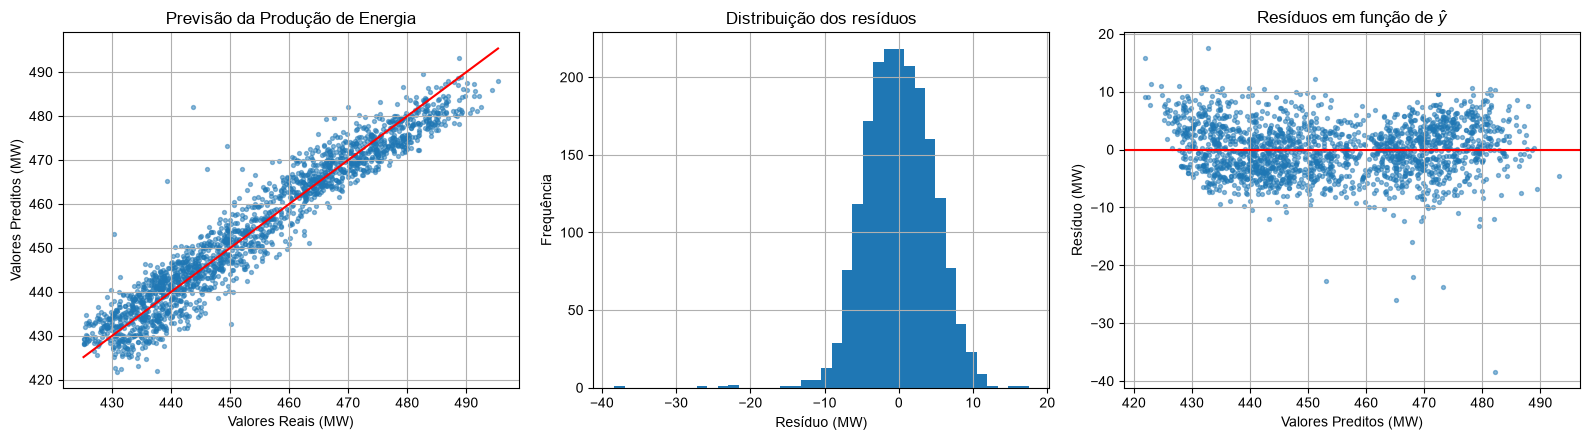

In [22]:
residuos = y_test - y_pred

y_ideal = np.linspace(np.min(y_test), np.max(y_test), 1000)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].plot(y_ideal, y_ideal, 'r')
ax[0].scatter(y_test, y_pred, s=8, alpha=0.5)
ax[0].set_xlabel("Valores Reais (MW)")
ax[0].set_ylabel("Valores Preditos (MW)")
ax[0].set_title("Previsão da Produção de Energia")

ax[1].hist(residuos, bins=40)
ax[1].set_xlabel("Resíduo (MW)")
ax[1].set_ylabel("Frequência")
ax[1].set_title("Distribuição dos resíduos")

ax[2].scatter(y_pred, residuos, s=8, alpha=0.5)
ax[2].axhline(0, color='r')
ax[2].set_xlabel("Valores Preditos (MW)")
ax[2].set_ylabel("Resíduo (MW)")
ax[2].set_title("Resíduos em função de $\\hat{y}$")

for a in ax:
    a.grid(True)
plt.tight_layout()
plt.savefig("figuras/diagnostico_modelo.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
print(f"Média dos resíduos: {residuos.mean():.4f} MW")
print(f"Menor e maior resíduo: {residuos.min():.2f} MW e {residuos.max():.2f} MW")

Média dos resíduos: 0.0149 MW
Menor e maior resíduo: -38.36 MW e 17.48 MW
